# LGD de recuperación: flujos, descuento y recuperaciones incompletas

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los cuadernos 01 y 02 del tema 01 (el motor y un artefacto)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- escribir la LGD realizada de un préstamo en incumplimiento como uno menos las recuperaciones netas descontadas sobre la exposición al incumplimiento, y calcularla a mano y con `workout_lgd`;
- decir qué hace la tasa de descuento a una LGD, y construir la tasa al estilo europeo con `eba_discount_rate`;
- marcar una LGD bajo 0 o sobre 1 con `range_flag`, y explicar por qué se conserva y nunca se recorta;
- decir por qué dejar fuera las recuperaciones abiertas sesga la LGD a la baja, y tratarlas de forma explícita con `resolve_incomplete` y `closed_before`;
- leer la LGD del caso C08, un proxy de castigos sobre los préstamos a pequeñas empresas SBA 7(a), y decir con exactitud en qué se diferencia de una LGD de recuperación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import workout

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Un artefacto versionado, `data/derived/C08/dc-2007-08.json`, la variante del caso C08 para los incumplimientos de 2007 y 2008. C08 se construye sobre el archivo público de préstamos SBA 7(a) (préstamos a pequeñas empresas, una fuente con espejo permitido), porque los campos de pérdida de Freddie Mac quedan derivados y fuera de línea en este producto. El archivo **no tiene flujos de recuperación**: registra el monto castigado y el monto aprobado. Por eso la LGD de C08 es un *proxy*, y el artefacto lo dice en `outputs.lgd_proxy`.

Por eso este cuaderno tiene dos mitades. La primera enseña la LGD de recuperación sobre un ejemplo trabajado pequeño, cuyos flujos están escritos en el cuaderno (cuatro préstamos inventados, rotulados como tales), porque las funciones `workout` del motor necesitan flujos. La segunda lee el artefacto C08 versionado y muestra qué es un proxy de castigos, qué oculta y cómo lo marca el motor. El artefacto fue horneado con un motor anterior al instalado aquí, así que la celda siguiente imprime la versión con que se horneó.

In [2]:
# Abrir el artefacto versionado e imprimir qué lo produjo, antes de usar un número suyo
ROOT = Path("../../..").resolve()
c08 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2007-08.json").read_text(encoding="utf-8"))
out = c08["outputs"]
WORD = {"real-outcomes": "resultados reales", "downward": "a la baja", "none-proxy": "ninguna (un proxy no tiene flujos)",
        "not-applicable": "no aplica", "in-range": "dentro del rango", "above-one": "sobre uno", "below-zero": "bajo cero",
        "excluded": "excluidas", "projected": "proyectadas"}
print("caso:", c08["case_id"], "| variante:", c08["variant_id"], "| cohorte:", out["cohort"]["label"]["es"])
print("estado de la verdad:", WORD[c08["provenance"]["truth_status"]])
print("horneado con riskvalidation:", c08["provenance"]["riskvalidation_version"], "| instalado:", rv.__version__)
print("fuente:", out["data_status"]["primary_source"], "| Freddie Mac disponible:", si_no(out["data_status"]["freddie_mac_available"]))

caso: C08 | variante: dc-2007-08 | cohorte: Incumplimientos 2007-08
estado de la verdad: resultados reales
horneado con riskvalidation: 0.6.0 | instalado: 0.8.1
fuente: sba-7a-chargeoff-twin | Freddie Mac disponible: no


## Método

### Paso 1: la LGD realizada de un préstamo

Para un préstamo en incumplimiento $i$ con exposición al incumplimiento $EAD_i$, el módulo `workout` del motor calcula

$$LGD_i = 1 - \frac{\sum_t (R_t - C_t - A_t)\,(1 + r_i)^{-t}}{EAD_i}$$

donde $R_t$ es una recuperación recibida en el momento $t$ (en años desde la fecha de incumplimiento), $C_t$ los costos directos e indirectos pagados en $t$, $A_t$ un giro adicional posterior al incumplimiento y $r_i$ la tasa de descuento. La suma es el valor presente, a la fecha de incumplimiento, de todo lo que el banco recuperó neto de lo que pagó; uno menos su parte de la exposición es la parte perdida. (Fuente: el docstring de `riskvalidation.lgd_ead.workout` en la versión 0.8.1; la regla de la tasa de descuento se describe en el paso 2.)

Abajo, cuatro préstamos inventados. Cada fila de los arreglos es un préstamo y cada columna una fecha de flujo. La primera celda los escribe y luego calcula el préstamo A **a mano**, un flujo a la vez, para que cada intermedio quede a la vista.

In [3]:
# Cuatro préstamos inventados en incumplimiento (A a D) con tres fechas de flujo cada uno, y el préstamo A a mano con una tasa de 8%
loans = ["A", "B", "C", "D"]
ead = np.array([100_000.0, 50_000.0, 80_000.0, 20_000.0])
times = np.array([[0.5, 1.0, 2.0], [0.25, 1.0, 1.5], [1.0, 2.0, 3.0], [0.5, 1.0, 1.5]])
recoveries = np.array([[30_000, 40_000, 20_000], [10_000, 15_000, 10_000], [5_000, 8_000, 2_000], [14_000, 9_000, 4_000]], dtype=float)
costs = np.array([[2_000, 2_000, 1_000], [3_000, 1_000, 500], [9_000, 7_000, 6_000], [500, 200, 100]], dtype=float)
drawings = np.zeros_like(recoveries)

rate = 0.08
total = 0.0
for k in range(3):
    net = recoveries[0, k] - costs[0, k] - drawings[0, k]
    factor = (1 + rate) ** (-times[0, k])
    total += net * factor
    print(f"préstamo A, flujo {k + 1}: t={times[0, k]:<4} neto={net:>9,.0f} factor de descuento={factor:.4f} valor presente={net * factor:>10,.2f}")
print(f"suma de valores presentes: {total:,.2f} | EAD: {ead[0]:,.0f} | LGD = 1 - {total:,.2f} / {ead[0]:,.0f} = {1 - total / ead[0]:.4f}")

préstamo A, flujo 1: t=0.5  neto=   28,000 factor de descuento=0.9623 valor presente= 26,943.01
préstamo A, flujo 2: t=1.0  neto=   38,000 factor de descuento=0.9259 valor presente= 35,185.19
préstamo A, flujo 3: t=2.0  neto=   19,000 factor de descuento=0.8573 valor presente= 16,289.44
suma de valores presentes: 78,417.64 | EAD: 100,000 | LGD = 1 - 78,417.64 / 100,000 = 0.2158


El mismo número sale de `workout_lgd`, que hace toda la tabla de una vez y rechaza la entrada mala (una EAD no positiva, un flujo negativo, un tiempo en o antes de la fecha de incumplimiento). La celda siguiente la llama para los cuatro préstamos con la misma tasa y compara el préstamo A con el cálculo a mano.

In [4]:
# Correr workout_lgd del motor con los cuatro préstamos y comparar el préstamo A con el cálculo a mano
lgd = workout.workout_lgd(ead, times, recoveries, costs, drawings, rate)
for name, value in zip(loans, lgd):
    print(f"préstamo {name}: LGD = {value:.4f}")
print("préstamo A, el motor coincide con el cálculo a mano:", si_no(np.isclose(lgd[0], 1 - total / ead[0])))

préstamo A: LGD = 0.2158
préstamo B: LGD = 0.4341
préstamo C: LGD = 1.0753
préstamo D: LGD = -0.2307
préstamo A, el motor coincide con el cálculo a mano: sí


### Paso 2: la tasa de descuento

La tasa importa: una recuperación a dos años vale menos a la fecha de incumplimiento que una que llega el próximo mes. La convención europea es una tasa interbancaria a la fecha de incumplimiento más un recargo; `eba_discount_rate(interbank_rate, add_on=0.05)` devuelve esa suma. El número de párrafo de la guía de la EBA detrás del recargo de 5% está marcado NO VERIFICADO en el propio motor, así que este cuaderno enuncia la convención y no cita un párrafo. Quien llama puede pasar cualquier otra tasa a `workout_lgd`. La celda siguiente construye la tasa para una interbancaria de 3% y recalcula las cuatro LGD con cuatro tasas, para ver la dirección: una tasa más alta reduce el valor presente de las recuperaciones netas y sube la LGD de un préstamo con flujos netos positivos (el préstamo C, de flujos netos negativos, es la excepción).

In [5]:
# Construir la tasa al estilo europeo y leer las cuatro LGD con varias tasas
eu_rate = workout.eba_discount_rate(0.03)
print("tasa al estilo europeo (3% interbancaria + 5% de recargo):", eu_rate)
print(f"{'tasa':>8s} " + " ".join(f"{'préstamo'} {n}".rjust(12) for n in loans))
for r in (0.0, 0.04, eu_rate, 0.12):
    row = workout.workout_lgd(ead, times, recoveries, costs, drawings, r)
    print(f"{r:8.2f} " + " ".join(f"{v:12.4f}" for v in row))

tasa al estilo europeo (3% interbancaria + 5% de recargo): 0.08
    tasa   préstamo A   préstamo B   préstamo C   préstamo D
    0.00       0.1500       0.3900       1.0875      -0.3100
    0.04       0.1844       0.4130       1.0810      -0.2688
    0.08       0.2158       0.4341       1.0753      -0.2307
    0.12       0.2447       0.4536       1.0703      -0.1952


### Paso 3: una LGD fuera de [0, 1] se conserva y se marca

El préstamo C paga más en costos de lo que recupera, así que su LGD está sobre 1. El préstamo D recupera más que su exposición (una venta de garantía sobre el valor libro), así que su LGD está bajo 0. Las carteras reales tienen ambos. El motor nunca recorta una LGD realizada: recortar escondería justo los casos que un validador necesita ver, y movería la media. `range_flag` rotula cada valor `below-zero`, `above-one` o `in-range`, de modo que el conteo de cada uno se informa junto a la distribución.

In [6]:
# Marcar cada LGD y comparar la media de los valores crudos con la media tras recortar a [0, 1]
flags = workout.range_flag(lgd)
for name, value, flag in zip(loans, lgd, flags):
    print(f"préstamo {name}: LGD = {value:8.4f} -> {WORD[str(flag)]}")
print(f"media de las LGD crudas: {lgd.mean():.4f} | media tras recortar a [0, 1]: {np.clip(lgd, 0, 1).mean():.4f}")

préstamo A: LGD =   0.2158 -> dentro del rango
préstamo B: LGD =   0.4341 -> dentro del rango
préstamo C: LGD =   1.0753 -> sobre uno
préstamo D: LGD =  -0.2307 -> bajo cero
media de las LGD crudas: 0.3736 | media tras recortar a [0, 1]: 0.4125


### Paso 4: recuperaciones incompletas

Un préstamo que cayó en incumplimiento hace poco aún se está recuperando: no han llegado todas sus recuperaciones. Si la LGD de una cartera se calcula solo sobre las recuperaciones *cerradas*, faltan las lentas, que suelen ser las peores, y la LGD queda sesgada a la baja. El motor hace del tratamiento un argumento explícito: `resolve_incomplete(lgd, complete, treatment)` con `treatment` igual a `"excluded"` (se descartan las abiertas y se cuentan) o `"projected"` (se reemplazan por una proyección entregada por quien llama). Devuelve cuántas se excluyeron o proyectaron, de modo que la elección nunca es silenciosa.

La celda siguiente inventa diez recuperaciones: seis cerradas, cuatro abiertas, con una proyección para cada abierta (los valores proyectados también son inventados). Muestra ambos tratamientos. `closed_before(close_dates, cutoff)` es la regla compañera para un conjunto de entrenamiento: una recuperación cuenta solo si cerró estrictamente antes del corte, y una abierta (sin fecha de cierre) nunca cuenta. El corte es el que usó el artefacto C08.

In [7]:
# Dos tratamientos de diez recuperaciones inventadas (seis cerradas, cuatro abiertas), y la regla del conjunto de entrenamiento con el corte de C08
lgd_ten = np.array([0.30, 0.45, 0.55, 0.60, 0.40, 0.65, np.nan, np.nan, np.nan, np.nan])
complete = np.array([True] * 6 + [False] * 4)
projected = np.array([np.nan] * 6 + [0.80, 0.85, 0.75, 0.90])

for treatment in ("excluded", "projected"):
    res = workout.resolve_incomplete(lgd_ten, complete, treatment, projected if treatment == "projected" else None)
    print(f"{WORD[treatment]:11s}: recuperaciones conservadas={res.lgd.size} excluidas={res.n_excluded} proyectadas={res.n_projected} LGD media={res.lgd.mean():.4f}")

cutoff = c08["outputs"]["training"]["cutoff_date"]
close_dates = np.array(["2005-06-30", "2006-12-30", "2006-12-31", "2007-03-15", "NaT"], dtype="datetime64[D]")
print("corte de C08:", cutoff)
for date, ok in zip(close_dates, workout.closed_before(close_dates, cutoff)):
    print(f"cerrada el {date}: entra al entrenamiento = {si_no(ok)}")

excluidas  : recuperaciones conservadas=6 excluidas=4 proyectadas=0 LGD media=0.4917
proyectadas: recuperaciones conservadas=10 excluidas=0 proyectadas=4 LGD media=0.6250
corte de C08: 2006-12-31
cerrada el 2005-06-30: entra al entrenamiento = sí
cerrada el 2006-12-30: entra al entrenamiento = sí
cerrada el 2006-12-31: entra al entrenamiento = no
cerrada el 2007-03-15: entra al entrenamiento = no
cerrada el NaT: entra al entrenamiento = no


### Paso 5: la LGD versionada del caso C08

Ahora el artefacto real. Su bloque `lgd_proxy` es lo primero que se lee: la definición, la fórmula, si existen flujos de recuperación y hacia dónde está sesgado el proxy. La celda imprime la definición y la declaración del sesgo en el idioma del cuaderno, y luego los números que da el proxy para la cohorte de incumplimientos 2007-08. Se calculan dos medias con los totales del propio artefacto: la media del proxy por préstamo (cada préstamo cuenta una vez) y la razón agrupada del total castigado sobre el total aprobado (cada dólar cuenta una vez). Difieren cuando préstamos de distinto tamaño pierden partes distintas.

In [8]:
# Imprimir la definición del proxy y su sesgo declarado, luego la media, la razón agrupada y las masas en 1 y sobre 1
proxy = out["lgd_proxy"]
print(proxy["definition"]["es"])
print()
print("Flujos de recuperación disponibles:", si_no(proxy["recovery_cash_flows_available"]), "| dirección del sesgo declarada:", WORD[proxy["bias_direction"]])
print(proxy["bias_statement"]["es"])
print()
dist = out["lgd_distribution"]
exposure = out["exposure"]
print(f"incumplimientos de la cohorte: {dist['n']:,} | tratamiento de valores fuera de [0, 1]: marcados, no recortados")
print(f"media del proxy por préstamo: {dist['mean']['value']:.4f} | mediana: {dist['median']['value']:.4f}")
print(f"razón agrupada, castigado sobre aprobado: {exposure['gross_charge_off_total'] / exposure['gross_approval_total']:.4f} ({exposure['currency']})")
print(f"exactamente 1: {dist['mass_at_one']['n']:,} ({dist['mass_at_one']['share']:.2%}) | sobre 1, conservados y marcados: {dist['n_above_one']:,} ({dist['share_above_one']:.2%}) | bajo 0: {dist['n_below_zero']}")

Proxy de LGD = monto bruto castigado sobre el monto bruto aprobado (campos SBA 7(a) GrossChargeOffAmount y GrossApproval, el único campo de exposición del archivo). Es un proxy, no una LGD de recuperación.

Flujos de recuperación disponibles: no | dirección del sesgo declarada: a la baja
El proxy tiene sesgo a la baja: el monto aprobado sobreestima la exposición al incumplimiento de un credito que se amortiza, de modo que el denominador es demasiado grande. Un segundo efecto va en sentido contrario: el archivo público SBA 7(a) no tiene flujos de recuperación posteriores al castigo, de modo que el proxy ignora recuperaciones y costos y sobreestima la pérdida neta de recuperaciones; también puede superar 1 si se castigan intereses capitalizados o comisiones. La dirección declarada es el efecto del denominador (decisión D2).

incumplimientos de la cohorte: 25,299 | tratamiento de valores fuera de [0, 1]: marcados, no recortados
media del proxy por préstamo: 0.8178 | mediana: 0.8901
razón 

La media del proxy por préstamo está muy sobre la razón agrupada, y una parte de los préstamos queda exactamente en 1 o sobre 1: el castigo igualó o superó el monto aprobado (los intereses capitalizados y las comisiones pueden llevarlo más arriba). Nada aquí se ha descontado, porque no hay flujos que descontar: el artefacto registra `discount_rate_convention` como `none-proxy`. La celda siguiente comprueba que los tramos del histograma y los valores marcados suman el tamaño de la cohorte, muestra el tratamiento que el propio artefacto da a las recuperaciones abiertas, y dibuja la distribución.

préstamos en los diez tramos de [0, 1]: 24,706 + sobre 1 593 + bajo 0 0 = 25,299 (cohorte 25,299)
convención de tasa de descuento: ninguna (un proxy no tiene flujos) | recuperaciones incompletas: no aplica
incumplimientos de entrenamiento: 48,833 | recuperaciones abiertas excluidas y contadas: 7,388


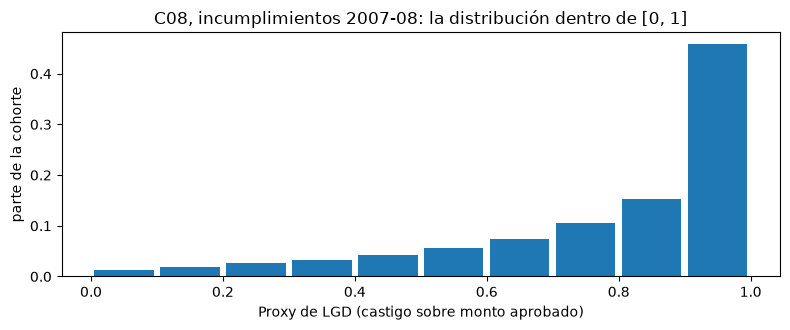

In [9]:
# Comprobar que los tramos y los valores marcados suman la cohorte, leer el bloque de recuperaciones y dibujar la distribución
bins = dist["bins"]
in_bins = sum(b["n"] for b in bins)
print(f"préstamos en los diez tramos de [0, 1]: {in_bins:,} + sobre 1 {dist['n_above_one']:,} + bajo 0 {dist['n_below_zero']} = {in_bins + dist['n_above_one'] + dist['n_below_zero']:,} (cohorte {dist['n']:,})")

wk = out["workout"]
print("convención de tasa de descuento:", WORD[wk["discount_rate_convention"]], "| recuperaciones incompletas:", WORD[wk["incomplete_workouts"]["treatment"]])
print("incumplimientos de entrenamiento:", f"{out['training']['n_defaults']:,}", "| recuperaciones abiertas excluidas y contadas:", f"{out['training']['n_open_workouts_excluded']:,}")

fig, ax = plt.subplots(figsize=(8, 3.4))
centres = [(b["lower"] + b["upper"]) / 2 for b in bins]
ax.bar(centres, [b["share"] for b in bins], width=0.09, color="tab:blue")
ax.set_xlabel("Proxy de LGD (castigo sobre monto aprobado)")
ax.set_ylabel("parte de la cohorte")
ax.set_title("C08, incumplimientos 2007-08: la distribución dentro de [0, 1]")
fig.tight_layout()
plt.show()

`lgd_distribution(lgd, edges)` del motor construye la misma tabla desde valores por préstamo: los conteos por tramo dentro de [0, 1], los valores fuera contados aparte y las masas exactas en 0 y 1. El artefacto guarda su resultado, no los valores por préstamo (el archivo SBA es un conjunto de terceros que no se versiona), así que esta última celda corre la función sobre las cuatro LGD inventadas del paso 1 con los bordes de tramo del propio artefacto, para mostrar qué devuelve y cómo deja fuera de los tramos los valores fuera de [0, 1].

In [10]:
# Correr lgd_distribution sobre las cuatro LGD inventadas con los bordes de tramo del artefacto
edges = np.array([bins[0]["lower"]] + [b["upper"] for b in bins])
table = workout.lgd_distribution(lgd, edges)
print("bordes:", edges)
print("conteos por tramo:", table.counts)
print(f"n={table.n} | bajo 0={table.n_below_zero} | sobre 1={table.n_above_one} | masa en 0={table.mass_zero} | masa en 1={table.mass_one}")

bordes: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
conteos por tramo: [0 0 1 0 1 0 0 0 0 0]
n=4 | bajo 0=1 | sobre 1=1 | masa en 0=0 | masa en 1=0


## Resultados

- **La LGD de recuperación es un valor presente.** El préstamo A tiene una LGD de 0,2158: las recuperaciones, netas de costos y descontadas a 8%, valen 78.417,64 frente a una exposición de 100.000 (el cálculo a mano y `workout_lgd` coinciden). En la tabla del paso 2 una tasa más alta sube la LGD de los préstamos A, B y D, y baja la del préstamo C, cuyos flujos netos son negativos, de modo que el descuento reduce lo que paga.
- **Fuera de [0, 1] es información.** El préstamo C, cargado de costos, está en 1,0753 y el D, sobrerrecuperado, en -0,2307; recortarlos mueve la media de los cuatro de 0,3736 a 0,4125.
- **Las recuperaciones abiertas deben tratarse, y el tratamiento es un número.** Excluir las cuatro recuperaciones abiertas da una LGD media de 0,4917; proyectarlas da 0,6250. Esa brecha es el sesgo a la baja del que advierte la investigación, y `resolve_incomplete` devuelve los conteos para que la elección sea visible. Las cuatro recuperaciones son inventadas, así que el tamaño de la brecha no dice nada de una cartera real.
- **C08 es un proxy, no una LGD de recuperación.** No hay flujos de recuperación, nada se descuenta, y el artefacto declara la dirección de su sesgo. Para la cohorte 2007-08 (25.299 incumplimientos) la media del proxy por préstamo es 0,8178 mientras que la razón agrupada del total castigado sobre el total aprobado es 0,6478. 3.204 préstamos (12,66%) están exactamente en 1 y 593 (2,34%) están sobre 1, conservados y marcados; ninguno está bajo 0.

Lo que el cuaderno no hace: no estima una LGD de recuperación para una cartera real, porque los datos versionados no tienen flujos. Los cuatro préstamos de los pasos 1 a 4 son inventados para mostrar la aritmética, y sus números no dicen nada de ningún prestamista. El cuaderno siguiente pasa a la otra mitad de la exposición, la exposición al incumplimiento y el factor de conversión de crédito.

## Resumen

- La LGD realizada es uno menos las recuperaciones netas descontadas sobre la EAD; `workout_lgd` la calcula para muchos préstamos a la vez y rechaza entradas inconsistentes.
- La tasa de descuento es una convención declarada (`eba_discount_rate` es la suma al estilo europeo de una tasa interbancaria y un recargo), y una tasa más alta sube la LGD de un préstamo cuyos flujos netos son positivos.
- Una LGD realizada fuera de [0, 1] se conserva y se marca con `range_flag`, nunca se recorta.
- Las recuperaciones abiertas sesgan la LGD a la baja si simplemente se omiten; `resolve_incomplete` hace explícito el tratamiento y `closed_before` enuncia la regla del conjunto de entrenamiento.
- La LGD versionada de C08 es un proxy de castigos sobre datos públicos de pequeñas empresas: sin flujos, sin descuento, con una dirección de sesgo declarada, y con valores sobre 1 conservados y marcados.

**Qué probar a continuación.** Cambia la tasa del paso 1 y los costos del préstamo C y mira cómo se mueven las LGD; luego sigue con el cuaderno 02, que hace lo mismo para la exposición al incumplimiento.

## Referencias

- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas: cálculo de activos ponderados por riesgo de crédito; los pisos de LGD y el tratamiento de la LGD en el enfoque avanzado). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424), los pisos de LGD del enfoque avanzado. https://www.bis.org/bcbs/publ/d424.htm
- La documentación del propio motor del módulo: `riskvalidation.lgd_ead.workout` (la fórmula, las marcas de rango y el tratamiento de recuperaciones incompletas, leídos de sus docstrings en la versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (caso C08, el gemelo de castigos SBA 7(a)) y `data/derived/C08/dc-2007-08.json` (`outputs.lgd_proxy`).